# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
# TODO: read PATIENTS_PATH with pd.read_csv
patients = pd.read_csv(PATIENTS_PATH)
# TODO: print the shape and the dtypes of patients
print(patients.shape)
print(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_point(filled=True, size=90).encode(
    x = alt.X('sessions_attended:Q', title='Sessions attended (of 36)'),
    y = alt.Y('walk_distance_m:Q', title='Six-minute walk distance (m)', scale=alt.Scale(zero=False)),
    color = alt.Color('program:N', title='Program'),
    shape = alt.Shape('program:N', title='Program'),
    tooltip = ('patient_id:N')
)  # TODO: the Altair scatter plot README Task 1.1 describes
exploratory_chart = exploratory_chart.properties(title='Scatter Plot of Sessions Attended vs Six-minute Walk Distance')
# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

#exploratory_chart.interactive()

(12, 4)
patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object


### 1.2 Describe what the chart shows

This chart is an attempt at tracking the relationship between physical therapy sessions and walking distance at discharge. Each point represents one patient and their 6-minute walking distance at discharge, and if the point is square the data was based at home. If the point is circular, the data was based in a center/clinic. The trend seems to be an upward line, showing that walking distance improves as more sessions are attended. This data is from a very small sample of 12 patients which means its statistical power is very low, therefore cannot draw any generalizable conclusions.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


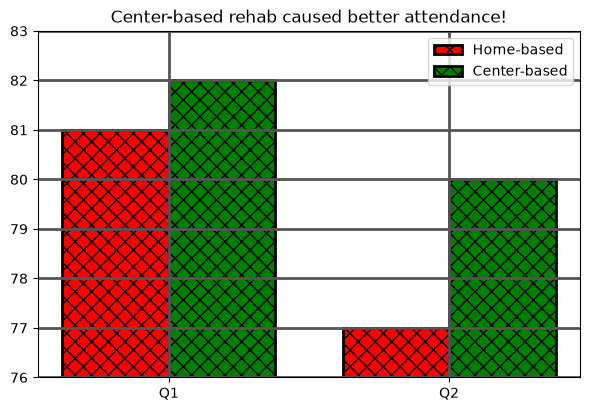

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", 
     "problem": "The title states that the plot shows a causal relationship, when it cannot show causality.", 
     "repair": "Number of attended sessions for center and home based programs during Q1 and Q2"},  # TODO: fill in each problem and repair
    {"category": "truncated baseline", 
     "problem": "The y-axis starts at 76 instead of 0, which can exaggerate differences in the data.", 
     "repair": "Start the y-axis at 0."},
    {"category": "missing unit", 
     "problem": "The y-axis label does not tell us what Q1 or Q2 represents.", 
     "repair": "Include the unit of Q1 and Q2 in the y-axis label."},
    {"category": "color-only encoding", 
     "problem": "The two programs are differentiated by color, which could be unhelpful to someone that is colorblind.", 
     "repair": "Use differentiated textures to show differences in program."},
    {"category": "distracting decoration", 
     "problem": "The textures of each program are not different for each category, therefore are unhelpful.", 
     "repair": "Change the texture of one of the categories so that someone who cannot see color can differentiate."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title states that the plot shows a causal relationship, when it cannot show causality.
    repair: Number of attended sessions for center and home based programs during Q1 and Q2
truncated baseline: The y-axis starts at 76 instead of 0, which can exaggerate differences in the data.
    repair: Start the y-axis at 0.
missing unit: The y-axis label does not tell us what Q1 or Q2 represents.
    repair: Include the unit of Q1 and Q2 in the y-axis label.
color-only encoding: The two programs are differentiated by color, which could be unhelpful to someone that is colorblind.
    repair: Use differentiated textures to show differences in program.
distracting decoration: The textures of each program are not different for each category, therefore are unhelpful.
    repair: Change the texture of one of the categories so that someone who cannot see color can differentiate.


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

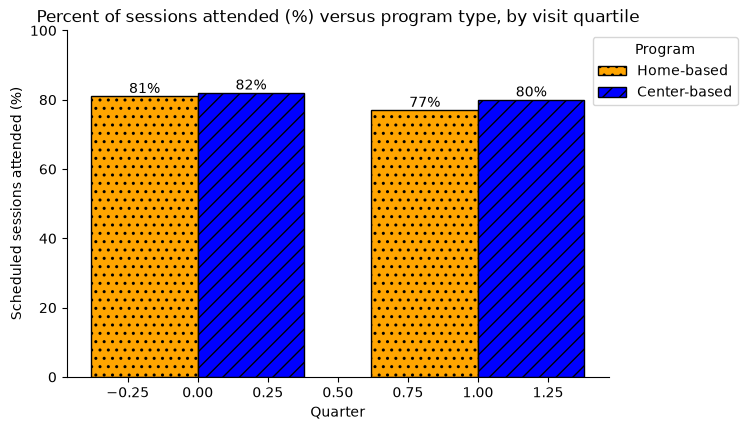

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

# TODO: draw the four bars again from home and center on redesign_ax, repairing each problem in your critique
# (README Task 2.3 lists the repairs)
home_bar = redesign_ax.bar(x - width / 2, home, width, label="Home-based", color="orange",
       hatch="..", edgecolor="black", linewidth=1)
center_bar = redesign_ax.bar(x + width / 2, center, width, label="Center-based", color="blue",
       hatch="//", edgecolor="black", linewidth=1)

redesign_ax.bar_label(home_bar, fmt='%d%%')
redesign_ax.bar_label(center_bar, fmt='%d%%')

redesign_ax.set_title("Percent of sessions attended (%) versus program type, by visit quartile")

redesign_ax.set_ylim(0, 100)
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_xlabel("Quarter")
redesign_ax.legend(title="Program", loc= "upper right", bbox_to_anchor=(1.25, 1))
redesign_ax.grid(False)
redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

# TODO: save redesign_fig to REDESIGN_PATH with dpi=150 and bbox_inches="tight"
redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")
plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)
# TODO: display followup
display(followup)
question = "Out of the visits recorded, how many of the weekly follow up exercises goals were met?"  # TODO: the comparison the chart should help the coordinator make
audience = "This chart is meant for the rehab program coordinator in order to decide where to add follow up support."  # TODO: who reads the chart and what they will use it for
intended_claim = "Attendance percentage is very similar in both clinic and home-based programs, across both quarters"  # TODO: the one descriptive conclusion the chart supports
y_measure = "The y axis shows the percentage (%) of weekly follow ups met."  # TODO: what the y-axis measures, with its unit
grain = "Each row represents one program per quarterly visit, with the number of patients seen that quarter and the percentage of patients that were successfully followed up with."  # TODO: what one row of the plotting table and one point on a line represent
data_types = {
    "program": "categorical",  # TODO: categorical, quantitative, ordinal, or temporal
    "visit_number": "ordinal",  # TODO
    "goal_met_pct": "quantitative",  # TODO
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]] # TODO: the three plotted columns of followup

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

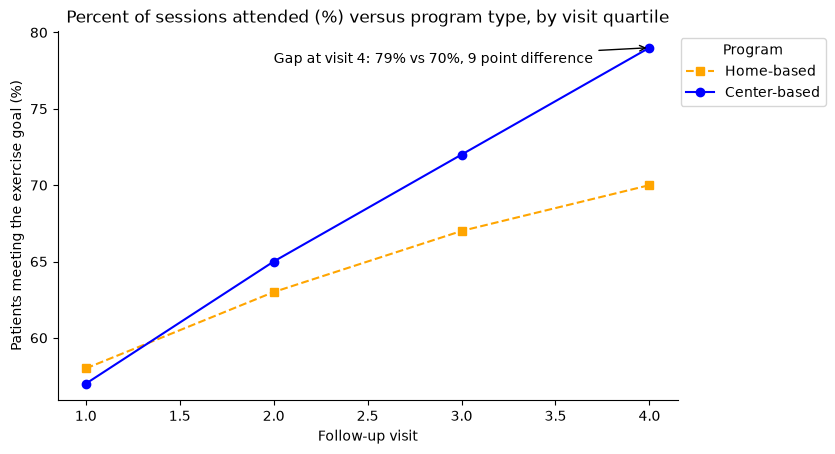

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"], label="Home-based",
                    color = "orange", marker = "s", linestyle = "--")
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"], label="Center-based",
                    color = "blue", marker = "o", linestyle = "-")

explanatory_ax.annotate('Gap at visit 4: 79% vs 70%, 9 point difference', xy=(4, 79), xytext=(2, 78),
                        arrowprops=dict(arrowstyle='->'))

explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)

explanatory_ax.set_title("Percent of sessions attended (%) versus program type, by visit quartile")

explanatory_ax.legend(title="Program", loc= "upper right", bbox_to_anchor=(1.25, 1))
# TODO: draw one line per program on explanatory_ax, with visit_number on x and goal_met_pct on y,
# and finish the chart as README Task 3.2 describes

# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")
plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = "This is a line chart, with each quarter of visits on the x-axis and the percentage of follow ups met on the y-axis. There are two lines, one for the Home-based program and one for the Center-based program. This line chart shows that home-based follow up rate is lower than the center-based follow up rate, with the largest gap between the two being at the final quarter [70% for home-based vs 79% for center-based]. A limitation for this chart is that the patients were able to freely choose their program so the groups may be skewed due to possible confounders."  # TODO: one paragraph, as README Task 3.3 describes

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)
# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH
with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?
-
1. For the bar chart, the user would be able to tell the difference between programs due to the different textures in the bars. For the line chart, there are two different textures of lines as well, according to program.
2. The annotation points to the fourth quarter data point which has the largest gap between the two programs. The point does not infer any conclusions, but points out that large gap by referencing the y access percentages and the difference between them.
3. In the final version of the charts, no text is cut off. I did have to make sure the annotation and the legend did not overlap with anything and I fixed this by changing their coordinates.
4. A limitation is that the chart only shows what data you have and visualizes it. It cannot check for sampling errors, possible confounders, or make conclusions.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m